# 4강 실습 · WAV 하나로 완성하는 Log-Mel 모델 입력

**학습 목표:** 공통 WAV를 STFT 파워 → Mel 파워 → Log-Mel 특징 → 모델 입력 배열로 변환합니다.

**실습 방법:** 처음부터 순서대로 실행하고 각 실습의 **확인해야 할 결과**를 관찰하세요. 자율실습은 TODO를 먼저 작성하고, 답안은 직접 해결한 뒤 확인합니다.

**공통 WAV:** `data/tone_sequence_16k_mono.wav` / 16kHz / 2초 / 440Hz와 880Hz. 파일이 없으면 실습에서 자동으로 만듭니다.

**최종 결과:** STFT `(257, 247)` → Mel `(40, 247)` → Log-Mel `(40, 247)` → 배치 `(1, 247, 40)`.


## 시작 준비 — 라이브러리 및 폴더 만들기

**실습 S-0 · 준비 셀:** 아래 셀을 가장 먼저 실행하세요.


In [32]:
# 목적: 분석에 필요한 라이브러리를 불러오고 실습용 data/results 폴더를 준비합니다.
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from pathlib import Path
from IPython.display import Audio, display
from scipy.io import wavfile
from scipy.signal import stft, resample_poly
from math import gcd
import json

# 한글 출력이 가능한 폰트가 있으면 그래프에 적용합니다.
fonts = {f.name for f in fm.fontManager.ttflist}
for name in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
    if name in fonts:
        plt.rcParams['font.family'] = name
        break
plt.rcParams['axes.unicode_minus'] = False  # 마이너스(-) 기호 깨짐 방지
plt.rcParams['figure.figsize'] = (10, 3)
plt.rcParams['figure.dpi'] = 110

DATA, RESULTS = Path('data'), Path('results')  # 입력·결과 폴더 경로
DATA.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
print('실습 폴더 준비:', DATA, RESULTS)

실습 폴더 준비: data results


---
## 1교시 · STFT에서 시간별 파워까지

**이번 교시의 목표:** 소리를 시간별 주파수 파워로 바꾸고 Mel이 필요한 이유 이해

**교시가 끝나면:** STFT 파워: (257, 247)


### 실습 1-A · 공통 WAV 생성·파형 확인

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 2초, 16kHz, 모노, 440Hz/880Hz


예제 합성음 생성: data\tone_sequence_16k_mono.wav
공통 실습 WAV: data\tone_sequence_16k_mono.wav / 2.00초 / 16kHz 모노
샘플 개수: 32000


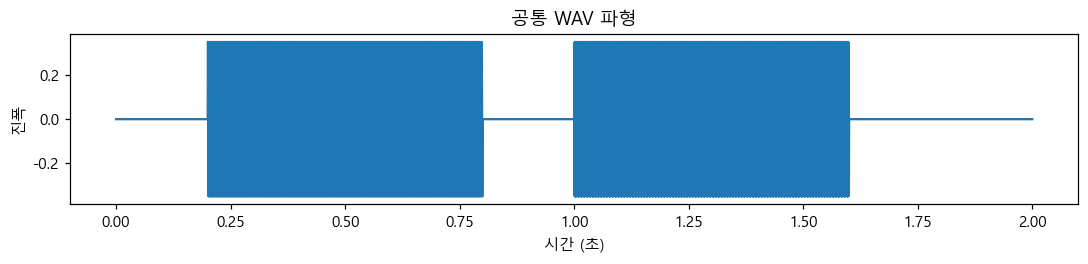

In [33]:
# 목적: 440Hz와 880Hz가 서로 다른 시간에 들어 있는 2초짜리 PCM16 합성음을 준비합니다.
# 예제 파일이 없으면 16kHz·2초 길이의 합성음을 생성
# 이후 STFT·Mel 실습에 사용할 2초 길이의 샘플 WAV 파일을 생성
# 16kHz·모노·PCM16 형식이며, 같은 경로에 파일이 없을 때만 만듭니다.
# 0.20~0.80초에는 440Hz, 1.00~1.60초에는 880Hz 소리를 넣고 나머지는 무음으로 둡니다.
# 시간과 주파수를 알고 있는 소리로 STFT·Mel 분석 결과를 확인하기 위한 예제입니다.
example_path = DATA / 'tone_sequence_16k_mono.wav'

if True:  # 매번 동일한 수업용 WAV로 덮어써서 실습 조건을 고정합니다.
    sample_times = np.arange(32000) / 16000  # 각 샘플의 시각(초)
    generated = np.zeros(32000, dtype=np.float32)  # 우선 전체를 무음으로 준비

    # 0.20~0.80초에는 440Hz, 1.00~1.60초에는 880Hz 소리 생성
    for start, end, tone_hz in [(0.20, 0.80, 440), (1.00, 1.60, 880)]:
        mask = (sample_times >= start) & (sample_times < end)  # 해당 구간 선택
        generated[mask] = 0.35 * np.sin(
            2 * np.pi * tone_hz * sample_times[mask]
        )  # 진폭 0.35인 사인파 입력

    # 실수 파형을 PCM16 정수로 변환하여 WAV 파일로 저장
    wavfile.write(
        example_path,
        16000,
        np.round(generated * 32767).astype(np.int16)
    )
    print('예제 합성음 생성:', example_path)
print("공통 실습 WAV:", example_path, "/ 2.00초 / 16kHz 모노")

print('샘플 개수:', len(generated))
plt.figure(figsize=(10, 2.5))
plt.plot(sample_times, generated)
plt.title('공통 WAV 파형')
plt.xlabel('시간 (초)'); plt.ylabel('진폭'); plt.tight_layout(); plt.show()


**실습 1-A 마무리:** 2초, 16kHz, 모노, 440Hz/880Hz.


### 실습 1-B · 하나의 WAV로 FFT와 STFT 비교

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 두 음이 발생하는 시간과 주파수 확인


0.5초의 강한 주파수: 437.5 Hz
1.2초의 강한 주파수: 875.0 Hz
공통 WAV 길이: 32000 샘플
STFT 파워 배열: (257, 247)


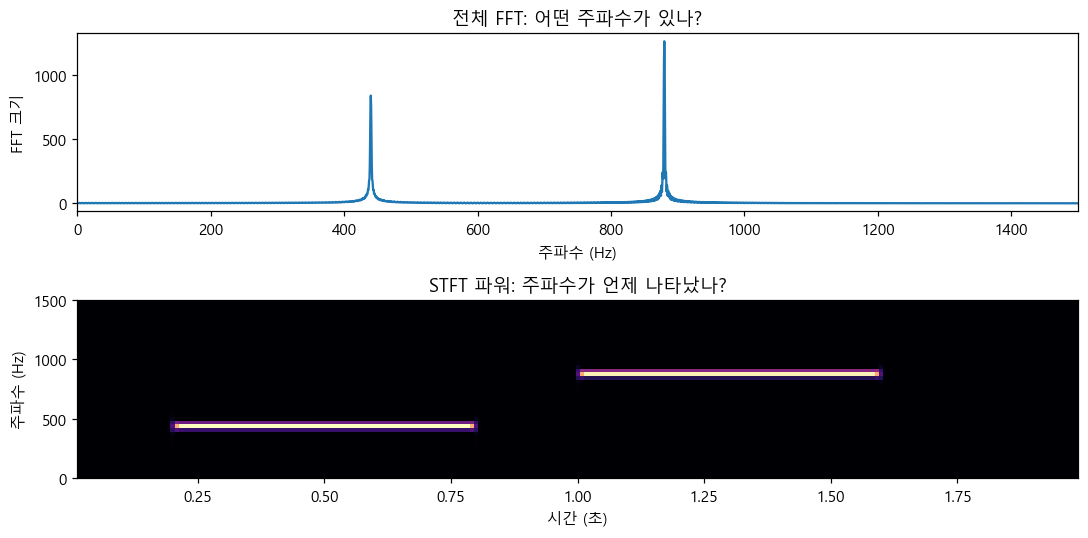

In [3]:
# 목적: 공통 2초 WAV에 들어 있는 440Hz·880Hz를 전체 FFT와 시간별 STFT에서 비교합니다.
fs_demo, pcm_demo = wavfile.read(DATA / 'tone_sequence_16k_mono.wav')
sound_demo = pcm_demo.astype(np.float32) / 32768.0

# 전체 FFT는 어떤 주파수가 포함됐는지 보여주지만 발생 시점을 표시하지 않습니다.
fft_hz = np.fft.rfftfreq(len(sound_demo), d=1/fs_demo)
fft_amplitude = np.abs(np.fft.rfft(sound_demo * np.hanning(len(sound_demo))))

# STFT는 512샘플 창을 128샘플씩 옮기며 시간별 주파수를 분석합니다.
stft_hz_demo, stft_time_demo, stft_values_demo = stft(
    sound_demo, fs=fs_demo, window='hann', nperseg=512, noverlap=384,
    nfft=512, boundary=None, padded=False, scaling='spectrum'
)
for moment in (0.5, 1.2):
    j = int(np.argmin(np.abs(stft_time_demo - moment)))
    k = int(np.argmax(np.abs(stft_values_demo[:, j])))
    print(f'{moment:.1f}초의 강한 주파수: {stft_hz_demo[k]:.1f} Hz')
print('공통 WAV 길이:', len(sound_demo), '샘플')
stft_power_demo = np.abs(stft_values_demo) ** 2  # 시간별 STFT 파워
print('STFT 파워 배열:', stft_power_demo.shape)
assert len(sound_demo) == 32000 and stft_values_demo.shape == (257, 247)

fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].plot(fft_hz, fft_amplitude)
axes[0].set(xlim=(0, 1500), xlabel='주파수 (Hz)', ylabel='FFT 크기', title='전체 FFT: 어떤 주파수가 있나?')
axes[1].pcolormesh(stft_time_demo, stft_hz_demo, stft_power_demo, shading='auto', cmap='magma')
axes[1].set(ylim=(0, 1500), xlabel='시간 (초)', ylabel='주파수 (Hz)', title='STFT 파워: 주파수가 언제 나타났나?')
plt.tight_layout(); plt.show()

**실습 1-B 마무리:** 두 음이 발생하는 시간과 주파수 확인.


### 실습 1-C · 낮은 음과 높은 음의 100Hz 차이 듣기

**실습 유형:** 관찰 · 실행 결과의 수치와 그림을 비교하세요.

**확인해야 할 결과:** 200→300Hz / 2,000→2,100Hz


In [4]:
# 목적: 같은 100Hz 차이를 낮은 음(200→300Hz)과 높은 음(2000→2100Hz)에서 들어 비교합니다.
sr = 16000  # 1초에 16,000개 샘플

def make_tone(hz):
    """지정한 주파수의 사인파를 0.8초 길이로 만듭니다."""
    t = np.arange(int(sr * 0.8)) / sr  # 각 샘플의 시각(초)
    sound = 0.2 * np.sin(2 * np.pi * hz * t)  # 진폭 0.2의 사인파

    # 소리 시작과 끝을 20ms 동안 서서히 줄여 경계의 클릭음을 완화합니다.
    fade = int(sr * 0.02)
    sound[:fade] *= np.linspace(0, 1, fade)
    sound[-fade:] *= np.linspace(1, 0, fade)
    return sound

pause = np.zeros(int(sr * 0.3))  # 두 음 사이 0.3초 무음
for title, first, second in [
    ('① 낮은 음: 200Hz → 300Hz', 200, 300),
    ('② 높은 음: 2,000Hz → 2,100Hz', 2000, 2100),
]:
    sound = np.concatenate([make_tone(first), pause, make_tone(second)])
    print(title)
    display(Audio(sound, rate=sr, normalize=False))  # 파형 직접 들어보기

① 낮은 음: 200Hz → 300Hz


② 높은 음: 2,000Hz → 2,100Hz


**실습 1-C 마무리:** 200→300Hz / 2,000→2,100Hz.


### 실습 1-D · Hz와 Mel 눈금 그래프

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 낮은 쪽 Mel 간격이 상대적으로 큼


[Hz와 Mel 변환값]
    0 Hz →     0.0 Mel
  500 Hz →   607.4 Mel
 1000 Hz →  1000.0 Mel
 2000 Hz →  1521.4 Mel
 4000 Hz →  2146.1 Mel
 8000 Hz →  2840.0 Mel
200→300Hz: 주파수 차이 100Hz / Mel 차이 118.7
2000→2100Hz: 주파수 차이 100Hz / Mel 차이 41.0


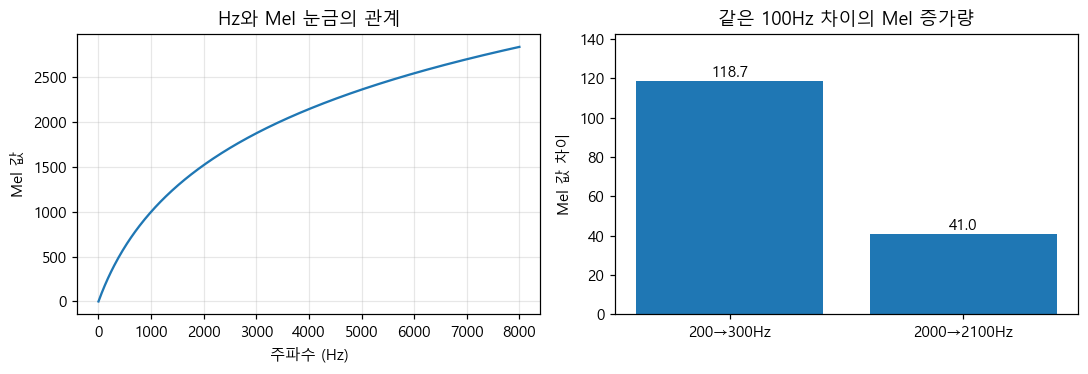

In [5]:
# 목적: Hz를 Mel 눈금으로 변환하고, 같은 100Hz 차이가 음역대에 따라 어떻게 달라지는지 확인합니다.

def hz_to_mel_intro(hz_value):
    """HTK 공식으로 Hz 값을 Mel 눈금으로 변환합니다(수학식의 유도는 학습 범위 밖)."""
    return 2595.0 * np.log10(1.0 + np.asarray(hz_value) / 700.0)

# 1. 대표적인 주파수를 Mel 눈금으로 변환해 비교합니다.
frequency_samples = [0, 500, 1000, 2000, 4000, 8000]
print('[Hz와 Mel 변환값]')
for hz_value in frequency_samples:
    print(f'{hz_value:5d} Hz → {hz_to_mel_intro(hz_value):7.1f} Mel')

# 2. Hz에 따른 Mel 값의 변화를 곡선으로 표시합니다.
hz_range = np.linspace(0, 8000, 401)  # 0~8,000Hz 사이 관찰용 주파수
mel_curve = hz_to_mel_intro(hz_range)

# 3. 같은 100Hz 차이를 낮은 구간과 높은 구간에서 비교합니다.
frequency_pairs = [(200, 300), (2000, 2100)]
mel_gaps = []
for first, second in frequency_pairs:
    gap = float(hz_to_mel_intro(second) - hz_to_mel_intro(first))
    mel_gaps.append(gap)
    print(f'{first}→{second}Hz: 주파수 차이 {second-first}Hz / Mel 차이 {gap:.1f}')

# 4. 왼쪽은 전체 Hz–Mel 관계, 오른쪽은 두 구간의 Mel 증가량입니다.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(hz_range, mel_curve)
axes[0].set(title='Hz와 Mel 눈금의 관계', xlabel='주파수 (Hz)', ylabel='Mel 값')
axes[0].grid(alpha=0.3)

axes[1].bar(['200→300Hz', '2000→2100Hz'], mel_gaps)
axes[1].set(title='같은 100Hz 차이의 Mel 증가량', ylabel='Mel 값 차이')
for i, gap in enumerate(mel_gaps):
    axes[1].text(i, gap + 2, f'{gap:.1f}', ha='center')  # 막대 위 숫자 표기
axes[1].set_ylim(0, max(mel_gaps) * 1.2)
plt.tight_layout()
plt.show()


**실습 1-D 마무리:** 낮은 쪽 Mel 간격이 상대적으로 큼.


### 실습 1-E · Hz 차이와 Mel 차이 계산

**실습 유형:** 자율실습 · TODO를 먼저 해결한 뒤 결과를 확인하세요.

**확인해야 할 결과:** 100Hz 차이가 Mel에서는 다르게 나타남


In [6]:
# 목적: 1교시 자율실습 — 주파수의 절대·상대 차이와 Mel 눈금 차이를 비교합니다.
# TODO 1: 아래 주파수 쌍을 반복문으로 처리하세요.
# TODO 2: 주파수 차이(Hz), 상대 변화율(%), Mel 값 차이를 출력하세요.
# TODO 3: 두 결과가 왜 다른지 출력 아래에 한 문장으로 적어 보세요.

frequency_pairs = [(200, 300), (2000, 2100)]
# 이 아래에 직접 코드를 작성하세요.


<details><summary><strong>실습 1-E · 정답 및 해설 펼치기 (먼저 스스로 작성하세요)</strong></summary>

#### 실습 1-E 정답 코드 — 직접 풀고 확인하세요

| 구간 | Hz 차이 | 상대 변화율 | Mel 차이 (약) |
|---|---:|---:|---:|
| 200→300Hz | 100Hz | 50.0% | 118.7 |
| 2,000→2,100Hz | 100Hz | 5.0% | 41.0 |

**해설:** 두 구간의 Hz 차이는 동일하지만 시작 주파수가 다릅니다. Mel 척도는 높은 주파수로 갈수록 같은 Hz 차이가 **더 작은 Mel 차이**가 되도록 설계되었습니다. 상대 변화율이 Mel 계산 공식 자체는 아니라는 점도 기억합니다.

</details>


In [7]:
# 목적: 1교시 정답 — 같은 100Hz 차이를 상대 변화율과 Mel 눈금으로 함께 비교합니다.
frequency_pairs = [(200, 300), (2000, 2100)]
for first, second in frequency_pairs:
    gap_hz = second - first                        # 물리적인 주파수 차이
    relative = gap_hz / first * 100                # 시작 주파수 대비 변화율
    gap_mel = hz_to_mel_intro(second) - hz_to_mel_intro(first)  # Mel 눈금 차이
    print(f'{first}→{second}Hz: 차이 {gap_hz}Hz / 상대 변화율 {relative:.1f}% / Mel 차이 {gap_mel:.1f}')


200→300Hz: 차이 100Hz / 상대 변화율 50.0% / Mel 차이 118.7
2000→2100Hz: 차이 100Hz / 상대 변화율 5.0% / Mel 차이 41.0


**실습 1-E 마무리:** 100Hz 차이가 Mel에서는 다르게 나타남.


---
## 2교시 · Mel 필터로 주파수 파워 묶기

**이번 교시의 목표:** 가중합 원리부터 실제 Mel 파워 생성까지

**교시가 끝나면:** Mel 파워: (40, 247)


### 실습 2-A · 네 주파수 파워를 두 특징으로 가중합

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** [2,4,8,2] → [4,6]


In [8]:
# 목적: 주파수 파워 4개에 가중치를 적용하여 Mel 필터와 비슷한 특징 2개를 계산합니다.
power_bins = np.array([2.0, 4.0, 8.0, 2.0]) # 한 시간 프레임의 네 주파수 칸의 파워
weights = np.array([[1.0, 0.5, 0.0, 0.0],
                    [0.0, 0.0, 0.5, 1.0]])
# @는 행렬 곱셈 연산자. 각 행의 가중치와 주파수 파워를 위치별로 곱한 후 모두 더함
grouped = weights @ power_bins             # 각 행의 가중치를 곱한 뒤 더함
print('원래 네 칸:', power_bins)
print('묶은 두 칸:', grouped)

원래 네 칸: [2. 4. 8. 2.]
묶은 두 칸: [4. 6.]


**실습 2-A 마무리:** [2,4,8,2] → [4,6].


### 실습 2-B · 가중합 전후 막대그래프

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 입력 4개와 출력 2개 비교


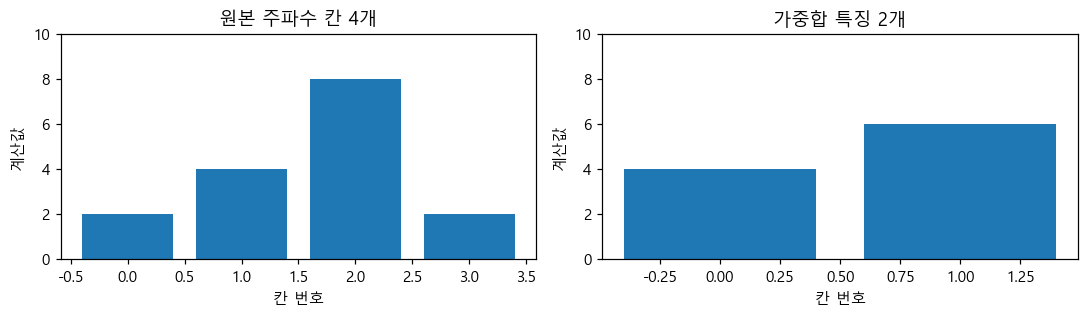

In [9]:
# 목적: 가중합 전의 주파수 칸 4개와 결과 특징 2개를 막대그래프로 비교합니다.
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].bar(range(4), power_bins)   # 원본 파워 4개
axes[0].set_title('원본 주파수 칸 4개')
axes[1].bar(range(2), grouped)      # 가중합 결과 2개
axes[1].set_title('가중합 특징 2개')
for ax in axes:
    ax.set(xlabel='칸 번호', ylabel='계산값', ylim=(0, 10))
plt.tight_layout()
plt.show()

# 왼쪽 그래프는 STFT 분석 후의 주파수별 파워를, 오른쪽 그래프는 Mel 필터로 가중합한 특징을 단순화하여 보여줍니다.
# 실제로는 257개 주파수 성분을 40개 Mel 특징으로 묶는 과정과 같은 원리입니다.

**실습 2-B 마무리:** 입력 4개와 출력 2개 비교.


### 실습 2-C · 첫 번째 필터 가중치 변경

**실습 유형:** 자율실습 · TODO를 먼저 해결한 뒤 결과를 확인하세요.

**확인해야 할 결과:** [4,6] → [3,6]


In [10]:
# 목적: 2교시 자율실습 — 원본 가중치를 보존한 채 첫 번째 필터만 수정해 결과를 비교합니다.
# TODO: weights.copy()로 복사하고 [0, 1]의 값을 0.25로 수정하세요.
# TODO: 원래 결과 grouped와 새 가중합을 출력하세요.
# 이 아래에 코드를 작성하세요.

<details><summary><strong>실습 2-C · 정답 및 해설 펼치기 (먼저 스스로 작성하세요)</strong></summary>

#### 실습 2-C 정답 및 해설

첫 번째 가중합은 `2×1 + 4×0.25 = 3`, 두 번째는 `8×0.5 + 2×1 = 6`입니다. **원본 주파수 파워가 바뀐 것이 아니라 첫 번째 필터의 가중치만 바뀌었습니다.**

</details>


In [11]:
# 목적: 첫 번째 필터의 가중치만 바뀌었을 때 출력이 [4, 6]에서 [3, 6]으로 변하는지 확인합니다.
changed = weights.copy()          # 원본 weights 유지
changed[0, 1] = 0.25             # 첫 번째 출력에만 영향을 주는 가중치 변경
changed_result = changed @ power_bins  # 변경된 필터로 가중합
print('변경 전:', grouped, '/ 변경 후:', changed_result)
print('원본 가중치 유지:', weights[0, 1] == 0.5)

변경 전: [4. 6.] / 변경 후: [3. 6.]
원본 가중치 유지: True


**실습 2-C 마무리:** [4,6] → [3,6].


### 실습 2-D · 공통 WAV 읽기 함수 준비

**실습 유형:** 함수 정의 · 이 셀에서 함수를 정의한 뒤 이후 실습에서 사용합니다.

**확인해야 할 결과:** PCM16 WAV → float32 파형


In [12]:
# 목적: PCM16 WAV를 실수 파형으로 읽고, 계산 설정·관찰 기록을 UTF-8 JSON으로 저장합니다.
def load_audio(path):
    """PCM16 WAV 파일 → (샘플링레이트, -1~1 부근의 float32 파형)."""
    path = Path(path)
    if not path.is_file():  # 파일이 실제로 존재하는지 검사
        raise FileNotFoundError(f'음성 파일이 없습니다: {path}')
    rate, samples = wavfile.read(path)  # WAV의 SR과 PCM 샘플 읽기
    if samples.dtype != np.int16 or samples.ndim not in (1, 2) or samples.size == 0:
        raise ValueError('샘플이 있는 PCM16 WAV(모노/스테레오) 파일만 사용합니다.')
    return int(rate), samples.astype(np.float32) / 32768.0  # 정수→실수 정규화


def save_json(path, obj):
    """설정과 관찰 결과를 한글이 유지되는 JSON 파일로 저장합니다."""
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding='utf-8')

**실습 2-D 마무리:** PCM16 WAV → float32 파형.


### 실습 2-E · 삼각형 Mel 필터 함수 준비

**실습 유형:** 함수 정의 · 이 셀에서 함수를 정의한 뒤 이후 실습에서 사용합니다.

**확인해야 할 결과:** 가중치 배열: (40,257)


In [13]:
# 목적: 삼각형 Mel 필터를 만들어 STFT 파워에 적용하고 Mel 파워를 반환합니다.
def apply_mel_filters(hz, power, sr, n_mels=40):
    """STFT 주파수별 파워 → (Mel 파워, Mel 필터 가중치)."""

    # Hz와 Mel 눈금을 서로 변환하는 HTK 공식(수학적 유도는 학습 범위 밖)
    hz_to_mel = lambda f: 2595.0 * np.log10(1.0 + f / 700.0)
    mel_to_hz = lambda mel: 700.0 * (10.0 ** (mel / 2595.0) - 1.0)

    # 필터 3개를 만들려면 기준점이 5개 필요(필터 개수 + 2 = 기준점 개수)
    # 40개 필터를 만들면 기준점은 42개가 필요
    # 1. Mel 눈금에서 n_mels+2개의 기준점을 일정한 간격으로 배치
    mel_edges = np.linspace(hz_to_mel(0), hz_to_mel(sr / 2), n_mels + 2)

    # 2. 각 기준점이 실제 몇 Hz인지 계산(원래 음성의 주파수가 바뀌지는 않음)
    edges = mel_to_hz(mel_edges)

    # 3. (Mel 필터 개수, STFT 주파수 칸 수) 형태의 가중치 표 준비
    filters = np.zeros((n_mels, len(hz)), dtype=np.float64)

    # 4. 왼쪽 0 → 중심 1 → 오른쪽 0인 삼각형 필터를 하나씩 생성
    for k in range(n_mels):
        left, center, right = edges[k:k+3]  # k번째 필터의 기준점 3개
        filters[k] = np.maximum(
            0,
            np.minimum(
                (hz - left) / (center - left),    # 왼쪽에서 중심으로 증가
                (right - hz) / (right - center)   # 중심에서 오른쪽으로 감소
            )
        )

    # 5. 주파수별 파워를 각 필터의 가중치로 묶어 Mel 파워 계산
    mel_power = filters @ power
    return mel_power, filters  # 특징 값과 필터 모양 확인용 배열


**실습 2-E 마무리:** 가중치 배열: (40,257).


### 실습 2-F · STFT 파워를 실제 Mel 파워로 변환

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** (257,247) → (40,247)


In [14]:
# 목적: 같은 WAV의 STFT 파워를 40개 Mel 필터로 가중합합니다. (아직 로그 변환하지 않음)
sr, audio = load_audio(DATA / 'tone_sequence_16k_mono.wav')
hz, times, spectrum = stft(
    audio, fs=sr, window='hann', nperseg=512, noverlap=384,
    nfft=512, boundary=None, padded=False, detrend=False, scaling='spectrum'
)
power = np.abs(spectrum) ** 2                   # (주파수 257, 시간 247)
mel_power, mel_filters = apply_mel_filters(hz, power, sr, n_mels=40)
print('입력 파형:', audio.shape, f'({len(audio)/sr:.2f}초)')
print('STFT 파워:', power.shape)
print('Mel 필터 가중치:', mel_filters.shape)
print('Mel 파워:', mel_power.shape)
assert power.shape == (257, 247)
assert mel_filters.shape == (40, 257)
assert mel_power.shape == (40, 247)
print('✓ 257개 주파수 파워가 40개 Mel 파워로 요약됐습니다. 로그 변환은 3교시에서 합니다.')

입력 파형: (32000,) (2.00초)
STFT 파워: (257, 247)
Mel 필터 가중치: (40, 257)
Mel 파워: (40, 247)
✓ 257개 주파수 파워가 40개 Mel 파워로 요약됐습니다. 로그 변환은 3교시에서 합니다.


**실습 2-F 마무리:** (257,247) → (40,247).


### 실습 2-G · 삼각형 필터와 Mel 파워 관찰

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 필터 가중치 그림 + 시간별 Mel 파워 그림


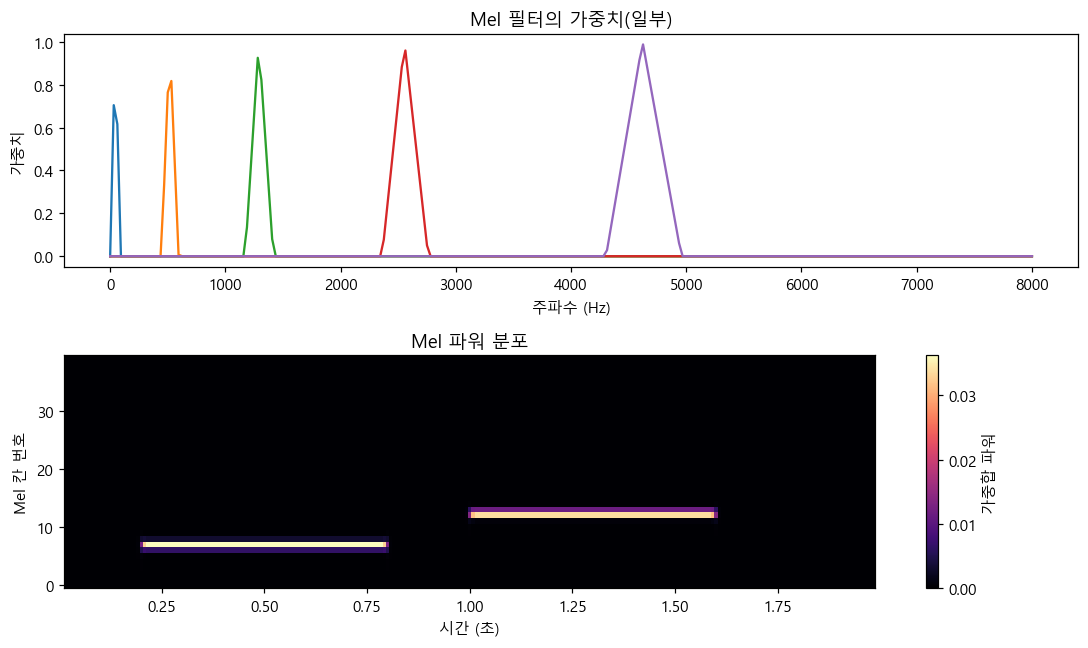

In [15]:
# 목적: Mel 필터의 삼각형 가중치와 시간에 따른 Mel 파워 분포를 시각화합니다.

# 위아래 2개의 그래프 생성
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# 1. Mel 필터의 삼각형 가중치 확인
# 전체 40개 필터 중 8개 간격으로 5개 필터를 선택하여 표시
# .T는 배열의 행과 열을 바꾸어 주파수별 가중치를 그래프로 표현
axes[0].plot(hz, mel_filters[::8].T)
axes[0].set(title='Mel 필터의 가중치(일부)',
            xlabel='주파수 (Hz)', ylabel='가중치')

# 2. 시간에 따른 Mel 파워 분포 확인
# 가로축: 시간, 세로축: Mel 필터 번호(0~39)
# 색상: 각 시간과 Mel 필터에서 계산된 파워의 크기
image = axes[1].pcolormesh(
    times,
    np.arange(40),
    mel_power,
    shading='auto',
    cmap='magma'
)
axes[1].set(title='Mel 파워 분포',
            xlabel='시간 (초)', ylabel='Mel 칸 번호')

# 색상의 의미를 나타내는 막대 추가
fig.colorbar(image, ax=axes[1], label='가중합 파워')

plt.tight_layout()
plt.show()

**실습 2-G 마무리:** 필터 가중치 그림 + 시간별 Mel 파워 그림.


---
## 3교시 · Mel 파워에서 Log-Mel 특징으로

**이번 교시의 목표:** 로그 변환 후 음성 특징의 시간 변화를 읽기

**교시가 끝나면:** Log-Mel: (40, 247)


### 실습 3-A · 숫자로 로그 변환 확인

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 1 → 0dB, 0.1 → -10dB


In [16]:
# 목적: 파워 1, 0.1, 0.01 등의 값을 로그 변환하여 dB 수치 변화와 바닥값을 확인합니다.
power_examples = np.array([1.0, 0.1, 0.01, 0.001, 0.0])
# 0에 로그를 계산하지 않도록 1e-10을 최소값으로 적용합니다.
db_examples = 10 * np.log10(np.maximum(power_examples, 1e-10))
for power_value, db_value in zip(power_examples, db_examples):
    print('파워', power_value, '→', round(float(db_value), 1), 'dB')

파워 1.0 → 0.0 dB
파워 0.1 → -10.0 dB
파워 0.01 → -20.0 dB
파워 0.001 → -30.0 dB
파워 0.0 → -100.0 dB


**실습 3-A 마무리:** 1 → 0dB, 0.1 → -10dB.


### 실습 3-B · 전체 logmel() 함수 정의

**실습 유형:** 함수 정의 · 이 셀에서 함수를 정의한 뒤 이후 실습에서 사용합니다.

**확인해야 할 결과:** STFT·Mel·로그를 묶어 재사용


In [17]:
# 목적: 모노 파형을 STFT 파워 → Mel 파워 → Log-Mel 특징으로 변환합니다.
def logmel(sound, sr, n_mels=40, frame_length=512, hop_length=128):
    """모노 파형 → STFT 파워 → Mel 파워 → Log-Mel(딕셔너리 반환)."""
    # n_mels: Mel 특징 수 / frame_length: 한 창의 샘플 수 / hop_length: 이동 샘플 수
    sound = np.asarray(sound)  # 입력 파형을 NumPy 배열로 변환

    # 모노 파형과 분석할 창 길이·이동 간격이 올바른지 검사
    if sound.ndim != 1 or not (1 <= hop_length <= frame_length <= len(sound)):
        raise ValueError('모노 파형과 유효한 창·이동 간격이 필요합니다.')

    # 이번 교육용 함수에서 허용하는 Mel 필터 개수인지 검사
    # 일반적인 Mel 변환의 절대적인 제한이 아니라 이 함수에서 정한 조건입니다.
    if not (2 <= n_mels < frame_length // 2):
        raise ValueError('Mel 칸 수가 올바르지 않습니다.')

    # 1. SciPy의 STFT: 한 시간 구간에서 여러 주파수 성분을 복소수로 계산
    hz, times, spectrum = stft(
        sound,
        fs=sr,                                  # 1초당 샘플 수
        window='hann',                          # 양 끝을 부드럽게 처리하는 창
        nperseg=frame_length,                    # 한 번에 분석할 샘플 수
        noverlap=frame_length - hop_length,      # 앞뒤 구간의 겹침 길이
        nfft=frame_length,                       # FFT 길이
        boundary=None,                          # 양쪽에 0을 덧붙이지 않음
        padded=False,                           # 마지막 구간도 0으로 채우지 않음
        detrend=False,                          # 별도의 평균값 제거 없음
        scaling='spectrum'                      # 스펙트럼 크기 기준
    )

    # 2. STFT 복소수의 크기를 제곱해 주파수별 파워 계산
    power = np.abs(spectrum) ** 2

    # 3. 별도 함수에서 삼각형 Mel 필터 생성 및 STFT 파워의 가중합 계산
    mel_power, filters = apply_mel_filters(hz, power, sr, n_mels)

    # 4. 0의 로그 계산을 방지한 뒤 파워에 로그를 취해 Log-Mel 생성
    log_mel = 10 * np.log10(np.maximum(mel_power, 1e-10))

    # 5. 특징과 함께 주파수·시간 축 및 계산 설정을 반환
    return {
        'power': power,          # STFT 파워: (주파수, 시간)
        'mel_power': mel_power,  # Mel 파워: (Mel, 시간)
        'log_mel': log_mel,      # Log-Mel: (Mel, 시간)
        'filters': filters,      # Mel 필터의 주파수별 가중치
        'hz': hz,                # STFT 주파수 칸의 위치(Hz)
        'times': times,          # 분석 시간 구간의 중심 시각(초)
        'config': {
            'sr': int(sr),
            'frame_length': frame_length,
            'hop_length': hop_length,
            'n_mels': n_mels,
            'mel_scale': 'HTK',
            'filter_normalization': 'none',
            'stft_window': 'hann',
            'stft_scaling': 'spectrum',
            'power_exponent': 2,
            'log_power_floor': 1e-10
        }
    }


**실습 3-B 마무리:** STFT·Mel·로그를 묶어 재사용.


### 실습 3-C · 공통 음성 Log-Mel 생성·모양 비교

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** STFT (257,247), Mel/로그 (40,247)


In [18]:
# 목적: 2초짜리 합성음을 STFT 파워 257칸과 Mel 파워 40칸으로 분석해 배열 모양을 확인합니다.
sr, audio = load_audio(DATA / 'tone_sequence_16k_mono.wav')
features = logmel(audio, sr, n_mels=40)   # 합성음의 Mel 특징 40개 추출
print('원본 파형:', audio.shape, '샘플 /', f'{len(audio)/sr:.2f}초')
print('STFT 파워 (주파수, 시간):', features['power'].shape)
print('Mel 파워 (Mel, 시간):', features['mel_power'].shape)
print('로그 Mel (Mel, 시간):', features['log_mel'].shape)
display(Audio(audio, rate=sr, normalize=False))  # 실제 파일의 소리 확인
# 2교시 Mel 파워 계산과 logmel() 내부의 가중합 결과가 일치하는지 확인합니다.
assert np.allclose(features['mel_power'], mel_power)
print('2교시 Mel 파워와 일치:', np.allclose(features['mel_power'], mel_power))

원본 파형: (32000,) 샘플 / 2.00초
STFT 파워 (주파수, 시간): (257, 247)
Mel 파워 (Mel, 시간): (40, 247)
로그 Mel (Mel, 시간): (40, 247)


2교시 Mel 파워와 일치: True


**실습 3-C 마무리:** STFT (257,247), Mel/로그 (40,247).


### 실습 3-D · Mel 파워와 Log-Mel 그래프 비교

**실습 유형:** 관찰 · 실행 결과의 수치와 그림을 비교하세요.

**확인해야 할 결과:** 색상 막대 수치까지 함께 확인


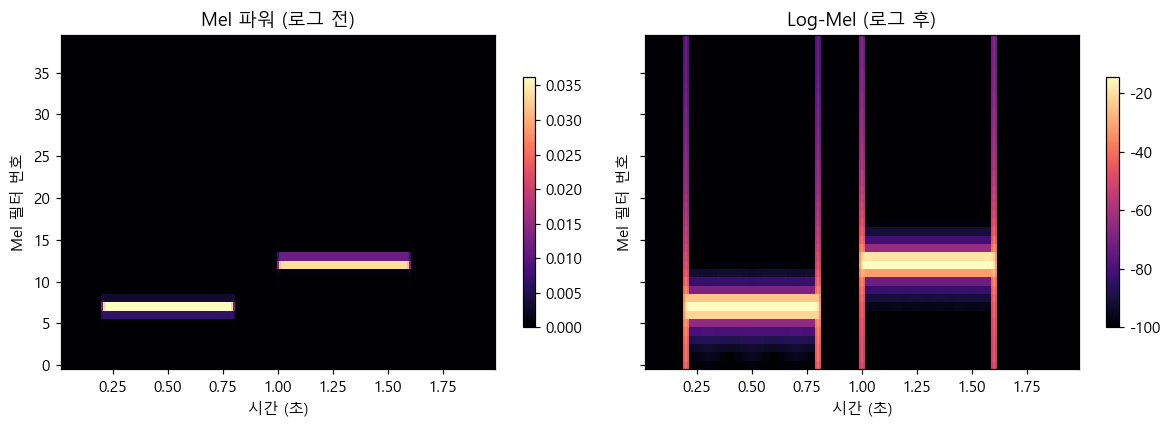

In [19]:
# 목적: 같은 음성의 Mel 파워와 Log-Mel을 나란히 비교하여 로그 변환의 효과를 관찰합니다.
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
# 두 그림 모두 동일한 시간 프레임과 Mel 필터 번호(0~39)를 사용합니다.
for ax, matrix, caption in zip(
    axes,
    [features['mel_power'], features['log_mel']],
    ['Mel 파워 (로그 전)', 'Log-Mel (로그 후)']
):
    m = ax.pcolormesh(features['times'], np.arange(40), matrix,
                      shading='auto', cmap='magma')
    ax.set(title=caption, xlabel='시간 (초)', ylabel='Mel 필터 번호')
    fig.colorbar(m, ax=ax, shrink=0.75)  # 그림별 눈금이 서로 다름에 유의
plt.tight_layout()
plt.show()
# 색의 밝기만 직접 비교하지 말고, 각 그래프의 색상 막대 숫자도 함께 읽어야 합니다.


**실습 3-D 마무리:** 색상 막대 수치까지 함께 확인.


### 실습 3-E · 시간별 강한 Mel 칸 번호

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 0.5초와 1.2초의 차이


In [20]:
# 목적: 0.5초와 1.2초에 가까운 시간 프레임에서 가장 강한 Mel 칸 번호를 관찰합니다.
for target in [0.5, 1.2]:
    column = int(np.argmin(np.abs(features['times'] - target)))  # 목표 시각에 가장 가까운 프레임
    band = features['mel_power'][:, column]                       # 해당 프레임의 Mel 40칸
    print(f'{target}초 → 가장 강한 Mel 칸: {int(np.argmax(band))}, 파워: {band.max():.6f}')

0.5초 → 가장 강한 Mel 칸: 7, 파워: 0.036236
1.2초 → 가장 강한 Mel 칸: 12, 파워: 0.033734


**실습 3-E 마무리:** 0.5초와 1.2초의 차이.


### 실습 3-F · Mel 특징 수 20개와 40개 비교

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** 주파수 특징 수만 변경


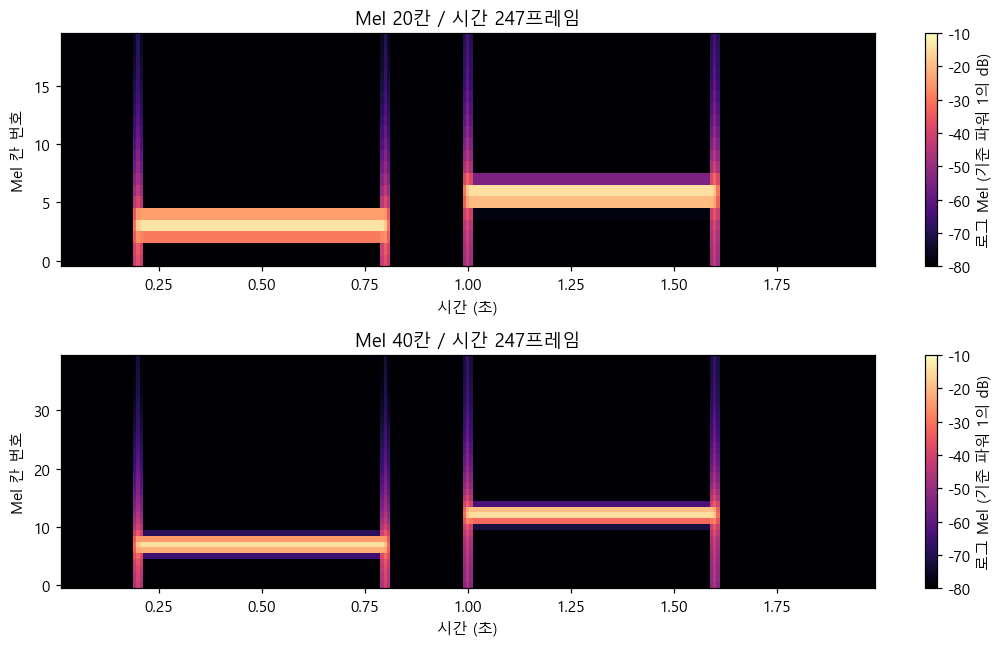

In [21]:
# 목적: 같은 소리를 Mel 20칸·40칸으로 계산해 세로축 해상도의 차이를 비교합니다.
fig, axes = plt.subplots(2, 1, figsize=(10, 6))
for ax, count in zip(axes, [20, 40]):
    current = logmel(audio, sr, n_mels=count)  # 특징 수만 변경하여 다시 계산
    image = ax.pcolormesh(current['times'], np.arange(count), current['log_mel'],
                          shading='auto', cmap='magma', vmin=-80, vmax=-10)
    ax.set(title=f'Mel {count}칸 / 시간 {len(current["times"])}프레임',
           xlabel='시간 (초)', ylabel='Mel 칸 번호')
    fig.colorbar(image, ax=ax, label='로그 Mel (기준 파워 1의 dB)')
plt.tight_layout()
plt.show()

**실습 3-F 마무리:** 주파수 특징 수만 변경.


### 실습 3-G · Mel 20·40 배열 크기 비교

**실습 유형:** 자율실습 · TODO를 먼저 해결한 뒤 결과를 확인하세요.

**확인해야 할 결과:** (20,247) / (40,247)


In [22]:
# 목적: 3교시 자율실습 — 특징 개수만 바꾸고 시간 프레임 수를 비교합니다.
# TODO: for 반복문과 logmel(audio, sr, n_mels=...)을 사용하세요.
# TODO: 각 결과의 log_mel.shape와 len(audio)/sr을 출력하세요.
# 이 아래에 코드를 작성하세요.

<details><summary><strong>실습 3-G · 정답 및 해설 펼치기 (먼저 스스로 작성하세요)</strong></summary>

#### 실습 3-G 정답 및 해설

**정답:** 기본 2초 합성음에서 Mel 20개는 `(20, 247)`, Mel 40개는 `(40, 247)`입니다. 주파수 정보를 묶는 출력 개수만 달라지고, 원본 길이·창·이동 간격이 같으므로 시간 프레임 수는 같습니다.

</details>


In [23]:
# 목적: 20개와 40개 Mel 특징의 배열 모양을 비교하여 Mel 축만 달라졌는지 검증합니다.
for count in [20, 40]:
    result = logmel(audio, sr, n_mels=count)  # 나머지 분석 설정은 동일
    print(f'Mel {count}개: {result["log_mel"].shape} / 음성 길이: {len(audio)/sr:.2f}초')

Mel 20개: (20, 247) / 음성 길이: 2.00초
Mel 40개: (40, 247) / 음성 길이: 2.00초


**실습 3-G 마무리:** (20,247) / (40,247).


---
## 4교시 · Log-Mel을 모델 입력으로 준비

**이번 교시의 목표:** 축 변경·배치·저장·선택 실음성 실습

**교시가 끝나면:** 모델 입력: (1, 247, 40)


### 실습 4-A · 특징·시간 배열의 축 바꾸기

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** (40,247) → (247,40)


In [24]:
# 목적: 로그 Mel 배열의 (특징, 시간)을 (시간, 특징)으로 전치합니다.
mel = features['log_mel'].astype(np.float32)  # 신경망 입력에 흔한 float32 형태
sequence = mel.T                             # (Mel, 시간) → (시간, Mel)
print('분석용:', mel.shape, '/ 시간 순서:', sequence.shape)
print('첫 시간 프레임의 특징 모양:', sequence[0].shape)

분석용: (40, 247) / 시간 순서: (247, 40)
첫 시간 프레임의 특징 모양: (40,)


**실습 4-A 마무리:** (40,247) → (247,40).


### 실습 4-B · 배치 축 직접 추가하기

**실습 유형:** 자율실습 · TODO를 먼저 해결한 뒤 결과를 확인하세요.

**확인해야 할 결과:** (247,40) → (1,247,40)


In [25]:
# 목적: 4교시 자율실습 — (Mel,시간)→(시간,Mel)→(배치,시간,Mel)로 변환합니다.
# TODO: features['log_mel']에서 시작하세요.
# TODO: .T, .astype(np.float32), [None, :, :]를 적용하고 각 shape를 출력하세요.
# 이 아래에 코드를 작성하세요.

<details><summary><strong>실습 4-B · 정답 및 해설 펼치기 (먼저 스스로 작성하세요)</strong></summary>

#### 실습 4-B 정답 및 해설

배치의 의미는 *현재 음성 파일 1개를 하나의 입력 묶음으로 만든 것*입니다. 실제 모델의 요구 축 순서가 다르면 모델 문서에 맞게 바꿔야 합니다.

**추가 확인 조건 예시:** SR, Mel 필터 수와 척도, 로그 및 정규화, 창/홉, 패딩 길이, 축 순서.

</details>


In [26]:
# 목적: 하나의 합성음을 (배치 1개, 시간 프레임, Mel 40개) 배열로 만들어 확인합니다.
sample = features['log_mel'].T.astype(np.float32)  # (시간, Mel)
batch = sample[None, :, :]                        # 맨 앞에 배치 축 추가
print('Mel·시간:', features['log_mel'].shape)
print('시간·Mel:', sample.shape)
print('배치·시간·Mel:', batch.shape)
assert batch.ndim == 3 and batch.shape[0] == 1 and batch.shape[2] == 40

Mel·시간: (40, 247)
시간·Mel: (247, 40)
배치·시간·Mel: (1, 247, 40)


**실습 4-B 마무리:** (247,40) → (1,247,40).


### 실습 4-C · 숫자 특징과 설정 저장·검증

**실습 유형:** 실행 · 아래 코드를 실행하고 결과를 확인하세요.

**확인해야 할 결과:** NPY + UTF-8 JSON


In [27]:
# 목적: 로그 Mel 숫자와 처리 조건을 별도 파일로 저장하고, 다시 읽어 값이 같은지 확인합니다.
np.save(RESULTS / 'lesson04_logmel.npy', mel)  # 특징 배열 저장
my_mel_explanation = '미작성: Mel 칸 번호와 Hz가 왜 다른지 적으세요.'
my_model_conditions = '미작성: 모델 입력 전 확인할 조건 두 가지를 적으세요.'
record = {
    'lesson': 4, 'example_id': 'tone_sequence', 'config': features['config'],
    'shape_mel_time': list(mel.shape),
    'Mel과_주파수축의_차이': my_mel_explanation,
    '모델에_넣기_전_확인할_조건': my_model_conditions
}
save_json(RESULTS / 'lesson04_record.json', record)  # 한글 포함 설정 저장
loaded = np.load(RESULTS / 'lesson04_logmel.npy')  # 저장된 숫자 파일 확인
print('저장 전후 값 동일:', np.array_equal(loaded, mel))

저장 전후 값 동일: True


**실습 4-C 마무리:** NPY + UTF-8 JSON.


### 실습 4-D · 실제 목소리 비교 (선택)

**실습 유형:** 선택 실습 · 파일이 있는 경우에만 실행합니다.

**확인해야 할 결과:** my_voice.wav가 있을 때만


원본: 48000Hz / 2채널 / 4.224초
변환: 16000Hz / 67584샘플 / 4.224초
로그 Mel (Mel, 시간): (40, 525)


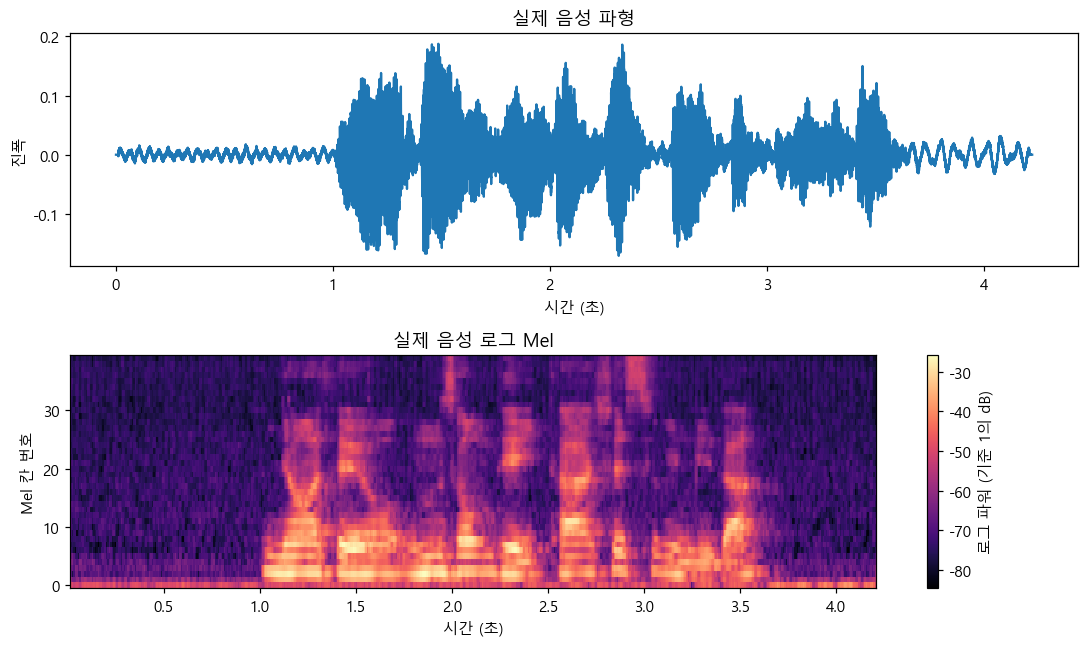

In [28]:
# 목적: 개인 녹음 파일이 있으면 모노·16kHz로 변환하고 로그 Mel 특징/그래프를 생성합니다.
voice_path = next((p for p in [DATA / 'my_voice.wav', Path('my_voice.wav')] if p.is_file()), None)
if voice_path is None:
    print('확장 실습 안내: my_voice.wav가 없으므로 실제 음성 실습만 건너뜁니다.')
    voice_features = None
else:
    voice_sr, voice_raw = load_audio(voice_path)  # PCM16 파일 읽기
    voice_channels = 1 if voice_raw.ndim == 1 else voice_raw.shape[1]  # 채널 확인
    voice_mono = voice_raw if voice_channels == 1 else voice_raw.mean(axis=1)  # 스테레오→모노
    common = gcd(voice_sr, 16000)  # 리샘플링 비율 간단히 만들기
    voice_16k = resample_poly(voice_mono, 16000 // common, voice_sr // common)
    if len(voice_16k) < 512:
        raise ValueError('0.032초 미만의 파일은 창 512샘플을 확보할 수 없습니다.')
    voice_features = logmel(voice_16k, 16000, n_mels=40)  # 실제 음성 Mel 계산
    voice_mel = voice_features['log_mel'].astype(np.float32)
    print(f'원본: {voice_sr}Hz / {voice_channels}채널 / {len(voice_mono)/voice_sr:.3f}초')
    print(f'변환: 16000Hz / {len(voice_16k)}샘플 / {len(voice_16k)/16000:.3f}초')
    print('로그 Mel (Mel, 시간):', voice_mel.shape)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6))
    axes[0].plot(np.arange(len(voice_16k)) / 16000, voice_16k)  # 모노 파형
    axes[0].set(xlabel='시간 (초)', ylabel='진폭', title='실제 음성 파형')
    im = axes[1].pcolormesh(voice_features['times'], np.arange(40), voice_mel,
                            shading='auto', cmap='magma')  # 시간별 로그 Mel
    axes[1].set(xlabel='시간 (초)', ylabel='Mel 칸 번호', title='실제 음성 로그 Mel')
    fig.colorbar(im, ax=axes[1], label='로그 파워 (기준 1의 dB)')
    plt.tight_layout()
    voice_fig = RESULTS / 'lesson04_my_voice_mel.png'
    fig.savefig(voice_fig, dpi=140, bbox_inches='tight')  # 그래프 저장
    plt.show()
    display(Audio(voice_16k, rate=16000, normalize=False))  # 변환 음성 재생

#### 선택 실습 4-D · 실제 음성 관찰 기록

아래 셀은 `my_voice.wav`를 준비한 학생만 실행합니다. 파일이 없으면 자동으로 건너뜁니다.


In [29]:
# 목적: 실제 목소리 분석 결과가 있을 때만 숫자 특징과 설정·관찰 기록을 저장합니다.
if voice_path is not None and voice_features is not None:
    voice_observation = '미작성: 발화 시각과 밝은 Mel 칸 범위를 적으세요.'
    voice_comparison = '미작성: 합성음과 실제 음성의 차이를 적으세요.'
    np.save(RESULTS / 'lesson04_my_voice_logmel.npy', voice_mel)  # 숫자 배열 저장
    voice_record = {
        'source_file': voice_path.name,
        'source_sr': voice_sr, 'source_channels': voice_channels,
        'processed_sr': 16000,
        'duration_seconds': round(len(voice_16k) / 16000, 4),
        'shape_mel_time': list(voice_mel.shape),
        'config': voice_features['config'],
        'figure': voice_fig.name,
        '관찰': voice_observation, '합성음과_비교': voice_comparison
    }
    save_json(RESULTS / 'lesson04_my_voice_record.json', voice_record)
    print('개인 음성 특징 및 관찰 기록 저장 완료')
else:
    print('개인 음성 파일 없음: 실제 음성 결과 저장은 건너뛰었습니다.')

개인 음성 특징 및 관찰 기록 저장 완료


**실습 4-D 마무리:** my_voice.wav가 있을 때만.


---
## 종합 P-1 · 하나의 WAV를 모델 입력 파일까지 완성

**문제 상황:** 다른 수강생이 여러분이 만든 Log-Mel 특징을 그대로 재현할 수 있어야 합니다.

**해야 할 일:** 입력 WAV 확인 → 필요시 전처리 → STFT·Mel·로그 특징 → 축 변경·배치 → 그림·배열·설정 저장 → 재읽기 검증.


In [30]:
# 목적: 종합 프로젝트 — WAV 읽기부터 입력 배열/그래프/결과 저장까지 직접 구현합니다.
# Step 1. PCM16 파일을 읽고 SR·채널 수·길이를 출력하세요.
# Step 2. 필요한 경우 모노와 16kHz로 변환하세요.
# Step 3. logmel()로 STFT 파워, 로그 Mel, 시간 값을 얻으세요.
# Step 4. 25%, 60% 시각에서 가장 큰 Mel 칸을 계산하세요.
# Step 5. (시간,Mel)→(1,시간,Mel) 배치를 만드세요.
# Step 6. np.save / save_json / plt.savefig로 3개 결과물을 저장하세요.
# Step 7. np.load와 np.array_equal로 저장값이 같은지 확인하세요.
# 이 아래에 코드를 작성하세요.

<details><summary><strong>종합 P-1 정답과 검증 체크 포인트 (직접 구현한 뒤 보세요)</strong></summary>

### Small Project 정답 코드와 검증 방법

아래는 **위쪽 실습에서 만든 `load_audio()`, `logmel()`, `save_json()`을 재사용** 하는 하나의 완성 예시입니다. 기본 입력은 합성음이므로 별도의 녹음 없이 실행됩니다.

- 기본 합성음 2초의 예상 출력: STFT `(257,247)`, 로그 Mel `(40,247)`, 배치 `(1,247,40)`.
- 본인 목소리로 바꾸면 시간 프레임 수는 음성 길이에 따라 달라질 수 있습니다.
- 이 코드의 Mel 입력은 **교육용 특징** 이며 Whisper 등 특정 음성 인식 모델의 공식 입력과 동일하다고 가정하면 안 됩니다.

</details>


입력: tone_sequence_16k_mono.wav / 16000Hz / 1채널 / 2.000초
전처리: 16000Hz / 2.000초
STFT 파워: (257, 247) 로그 Mel: (40, 247)
모델 입력 배치: (1, 247, 40)
시각별 강한 Mel 칸: [{'requested_time_s': 0.5, 'actual_time_s': 0.496, 'peak_mel_index': 7}, {'requested_time_s': 1.2, 'actual_time_s': 1.2, 'peak_mel_index': 12}]


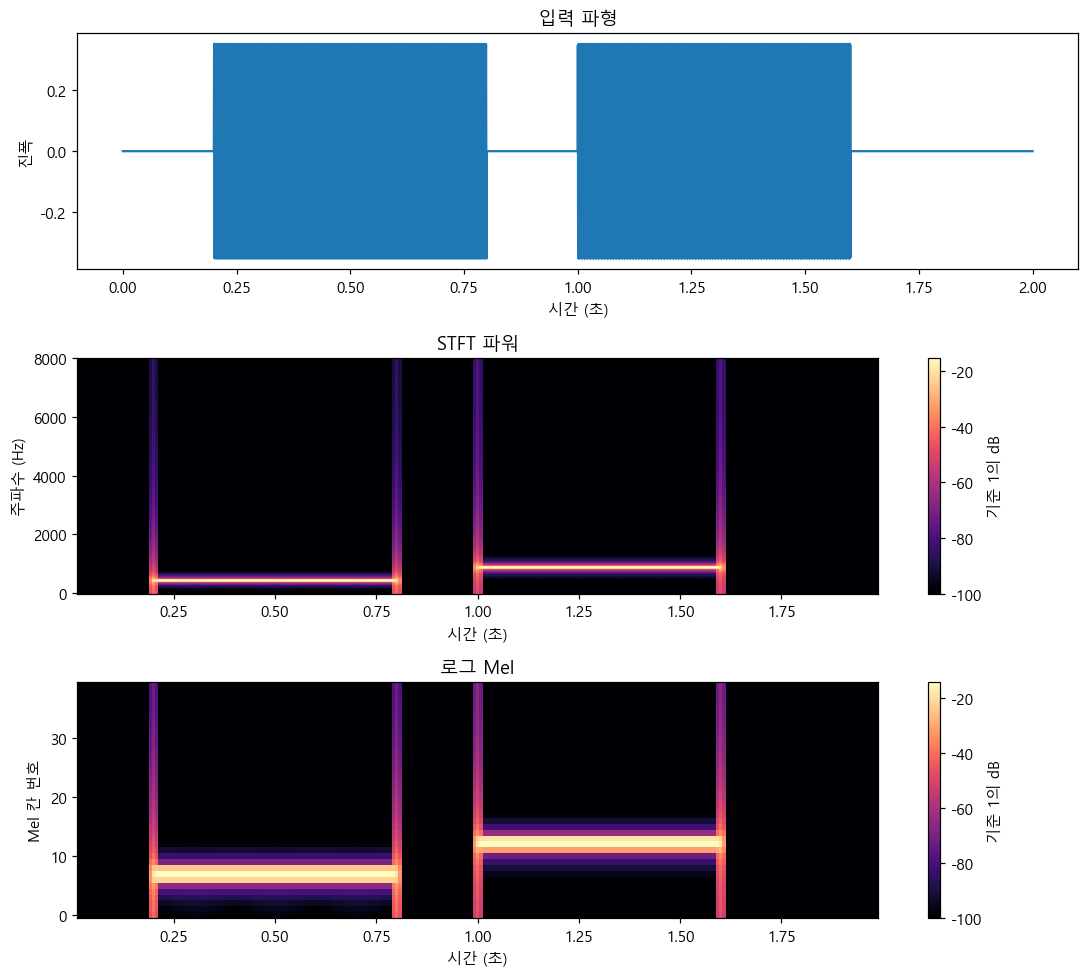

검증 성공: 저장 전후 특징 배열이 일치하며 결과물 3개가 생성되었습니다.


In [31]:
# 목적: Small Project 정답 — 음성을 전처리하고 STFT·로그 Mel·모델 입력 배열을 저장·검증합니다.
project_path = DATA / 'tone_sequence_16k_mono.wav'  # 기본 입력. 준비했다면 DATA/'my_voice.wav'로 변경 가능
project_sr, project_raw = load_audio(project_path)
project_channels = 1 if project_raw.ndim == 1 else project_raw.shape[1]  # 채널 수 확인
project_mono = project_raw if project_channels == 1 else project_raw.mean(axis=1)  # 모노 변환

# 샘플링레이트가 다른 경우만 폴리페이즈 리샘플링을 수행합니다.
if project_sr == 16000:
    project_16k = project_mono
else:
    factor = gcd(project_sr, 16000)
    project_16k = resample_poly(project_mono, 16000 // factor, project_sr // factor)

if len(project_16k) < 512:
    raise ValueError('음성 길이가 너무 짧습니다: 512샘플 이상이 필요합니다.')

# 같은 시간 프레임에 대해 STFT 파워→Mel 파워→로그 Mel을 계산합니다.
project_features = logmel(project_16k, 16000, n_mels=40,
                          frame_length=512, hop_length=128)
project_power = project_features['power']
project_logmel = project_features['log_mel'].astype(np.float32)
project_sample = project_logmel.T                       # (시간, Mel)
project_batch = project_sample[None, :, :]             # (배치, 시간, Mel)

# 25%, 60% 지점의 실제 시간 프레임에서 최대 Mel 칸 번호를 관찰합니다.
project_duration = len(project_16k) / 16000
project_peaks = []
for portion in [0.25, 0.60]:
    target_time = project_duration * portion
    column = int(np.argmin(np.abs(project_features['times'] - target_time)))
    mel_index = int(np.argmax(project_features['mel_power'][:, column]))
    project_peaks.append({'requested_time_s': round(target_time, 3),
                          'actual_time_s': round(float(project_features['times'][column]), 3),
                          'peak_mel_index': mel_index})

print(f'입력: {project_path.name} / {project_sr}Hz / {project_channels}채널 / {len(project_mono)/project_sr:.3f}초')
print(f'전처리: 16000Hz / {project_duration:.3f}초')
print('STFT 파워:', project_power.shape, '로그 Mel:', project_logmel.shape)
print('모델 입력 배치:', project_batch.shape)
print('시각별 강한 Mel 칸:', project_peaks)

# 분석 그림: 파형 / STFT 파워(dB) / 로그 Mel(dB)을 같은 시간 축으로 살펴봅니다.
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
axes[0].plot(np.arange(len(project_16k)) / 16000, project_16k)
axes[0].set(title='입력 파형', xlabel='시간 (초)', ylabel='진폭')
stft_db = 10 * np.log10(np.maximum(project_power, 1e-10))  # STFT 파워를 로그 눈금으로 변환
im1 = axes[1].pcolormesh(project_features['times'], project_features['hz'],
                          stft_db, shading='auto', cmap='magma')
axes[1].set(title='STFT 파워', xlabel='시간 (초)', ylabel='주파수 (Hz)')
fig.colorbar(im1, ax=axes[1], label='기준 1의 dB')
im2 = axes[2].pcolormesh(project_features['times'], np.arange(40),
                          project_logmel, shading='auto', cmap='magma')
axes[2].set(title='로그 Mel', xlabel='시간 (초)', ylabel='Mel 칸 번호')
fig.colorbar(im2, ax=axes[2], label='기준 1의 dB')
plt.tight_layout()
fig.savefig(RESULTS / 'project04_plot.png', dpi=130, bbox_inches='tight')
plt.show()

# 숫자 배열과 계산 방법을 함께 저장하여 재현 가능하게 합니다.
np.save(RESULTS / 'project04_features.npy', project_batch)
project_report = {
    'input_file': project_path.name, 'input_sr': project_sr,
    'input_channels': project_channels, 'processed_sr': 16000,
    'duration_s': round(project_duration, 3),
    'stft_power_shape': list(project_power.shape),
    'log_mel_shape': list(project_logmel.shape),
    'batch_shape': list(project_batch.shape),
    'peak_mel_examples': project_peaks,
    'config': project_features['config'],
    'interpretation': 'Mel 칸은 주파수 대역의 가중합이며 Hz 값 자체가 아닙니다.'
}
save_json(RESULTS / 'project04_report.json', project_report)
reloaded = np.load(RESULTS / 'project04_features.npy')
assert project_batch.shape[0] == 1 and project_batch.shape[-1] == 40
assert np.array_equal(reloaded, project_batch), '저장한 특징 배열이 다릅니다.'
print('검증 성공: 저장 전후 특징 배열이 일치하며 결과물 3개가 생성되었습니다.')

### 프로젝트 결과 확인 및 자기 평가

| 확인 항목 | 확인 방법 | 완료 |
|---|---|---|
| 입력 음성 정보 확인 | 채널·SR·길이가 출력됨 | □ |
| 전처리 수행 | 필요할 때 모노 변환·실제 리샘플링 | □ |
| STFT·Mel 차이 설명 | 주파수 257칸이 Mel 40칸으로 바뀜 | □ |
| 로그 변환 의미 설명 | 큰 값 차이의 로그 표현, 잡음 제거 아님 | □ |
| 모델 입력 배열 완성 | `(1, 시간, 40)` 모양 | □ |
| 결과물 검증 | `project04_features.npy`, `project04_report.json`, `project04_plot.png` 존재 | □ |

**마무리 정리:** STFT는 시간별 주파수를 자세히 분석하고, Mel은 사람이 설계한 필터로 주파수 칸을 묶고, 로그는 값의 범위를 변환합니다. 이후 신경망은 이 특징을 입력받아 *학습 목적에 필요한 표현*을 학습할 수 있습니다.

**다음 5강 연결:** 지금 만든 음성 특징을 **음성 파일·정답·데이터 분할·길이 맞추기**와 연결합니다.
